# Segmentação da árvore vascular da retina — Projeto Final

**Processamento Digital de Imagens**

Este notebook desenvolve, etapa por etapa, o projeto de segmentação de vasos da retina descrito no relatório técnico. Ele carrega imagens coloridas do FIVES, extrai o canal verde, realça vasos com CLAHE e top-hat, segmenta por histerese, limpa a máscara com morfologia, esqueletiza a árvore vascular, calcula métricas e executa comparações e análises de falhas.


### O que foi realizado

- comparações de realce e limiarização com Dice, IoU, sensibilidade e especificidade;
- estudo univariado da sensibilidade dos parâmetros e estudo de ruído/PSNR;
- métricas de validação interna e avaliação no teste oficial de segmentação, comprimento e ramificações;
- figura das etapas do pipeline e mapas de erro;
- arquivos CSV e previsões opcionais do split oficial de teste.



## 1. Preparação do ambiente

Instalamos bibliotecas para leitura de imagens, filtros, morfologia, esqueletização, estatística e gráficos. O código roda em CPU; GPU não é necessária para este método clássico.

In [6]:
%pip -q install opencv-python-headless scikit-image scipy pandas matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [7]:
import os, zipfile, urllib.request, json, shutil, time, warnings
import re
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import convolve
from scipy.stats import wilcoxon
from skimage.morphology import skeletonize
from skimage.filters import threshold_otsu, threshold_local, apply_hysteresis_threshold, frangi
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
print('OpenCV', cv2.__version__, '| NumPy', np.__version__)


OpenCV 5.1.0 | NumPy 2.2.6


## 2. Obtenção e inspeção do FIVES

O notebook usa o espelho público do conjunto hospedado no Kaggle. A documentação oficial do FIVES informa que o dataset contém 800 imagens de fundo de olho de alta resolução (2048×2048), divididas em 600 imagens para treino e 200 para teste, todas com anotações pixel a pixel (ground truth) disponíveis na própria estrutura do conjunto. A licença original indicada no Figshare é CC BY 4.0, mas o espelho consultado no Kaggle não especifica claramente a licença (aparece como “Unknown” ou em branco), então verifique as condições de uso antes de redistribuir os dados. [2]

O arquivo baixado é extraído para /content/FIVES. A estrutura esperada contém as pastas train/ e test/, cada uma com as subpastas Original/ (imagens originais) e Ground truth/ (máscaras de vasos anotadas). Se o provedor alterar o endpoint, baixe o arquivo manualmente e coloque a pasta FIVES/ no armazenamento do Colab ou no diretório local `content/`, mantendo essa estrutura de diretórios.


In [8]:
# Diretório de dados no Google Colab
# FOLDER_PATH = '/content/'

# Diretório de dados no ambiente local
FOLDER_PATH = '/content/'

In [9]:
FIVES_PARAMS = {
    "DOWNLOAD_URL": 'https://www.kaggle.com/api/v1/datasets/download/arfaahmed/fives-dataset',
    "EXTENSION": '.png',
    "PATH_FOR_DATA": FOLDER_PATH + '/FIVES',
    "PATH_TO_ZIP": FOLDER_PATH + '/FIVES.zip',
    "TRAIN_SPLIT": 'train',
    "PATH_TO_IMAGES": 'train/Original',
    "PATH_TO_MASKS": 'train/Mask', 
    "LIMIT_SAMPLES": 20
}

DATASET_PARAMS = {'FIVES': FIVES_PARAMS}

DATASET = "FIVES"
DATABASE = DATASET_PARAMS[DATASET]

DOWNLOAD_URL = DATABASE["DOWNLOAD_URL"]
EXTENSION = DATABASE["EXTENSION"]
DATA_ROOT = Path(DATABASE["PATH_FOR_DATA"])
ZIP_PATH = Path(DATABASE["PATH_TO_ZIP"])
PATH_TO_IMAGES = Path(DATABASE["PATH_FOR_DATA"]) / Path(DATABASE["PATH_TO_IMAGES"])
PATH_TO_MASKS = Path(DATABASE["PATH_FOR_DATA"]) / Path(DATABASE["PATH_TO_MASKS"])
SPLIT = DATABASE["TRAIN_SPLIT"]
LIMIT_SAMPLES = DATABASE["LIMIT_SAMPLES"]

In [10]:
os.makedirs(FOLDER_PATH, exist_ok=True)
if not os.path.exists(PATH_TO_IMAGES):
    print('Baixando a cópia pública do dataset…')
    urllib.request.urlretrieve(DOWNLOAD_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(FOLDER_PATH)
    print('Extraído em', DATA_ROOT)
folder = Path(FOLDER_PATH) / 'FIVES A Fundus Image Dataset for AI-based Vessel Segmentation'
if folder.exists() and not DATA_ROOT.exists():
    folder.rename(DATA_ROOT)
    print('Pasta do FIVES organizada em',DATA_ROOT)

print('Imagens anotadas no treino:', len(list((PATH_TO_IMAGES).glob(f"*{EXTENSION}"))))
print('Imagens no split oficial de teste:', len(list((DATA_ROOT/'test'/'Original').glob('*.png'))))

Imagens anotadas no treino: 600
Imagens no split oficial de teste: 200


In [11]:
def generate_masks(images_path, mask_path, extension=EXTENSION):
    """Gera máscaras de campo de visão para imagens sem arquivo de máscara."""
    os.makedirs(mask_path, exist_ok=True)
    
    # Processa cada imagem e preserva máscaras que já existem.
    for image_file in os.listdir(images_path):
        if image_file.endswith(extension):
            image_path = os.path.join(images_path, image_file)
            masked_path = os.path.join(mask_path, f"mask_{image_file}")
            if os.path.exists(masked_path):
                continue
            image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
            if image is None:
                raise FileNotFoundError(f"Não foi possível ler {image_path}")
            
            # Estima o campo de visão pelo limiar de Otsu.
            _, mask = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            
            print(f"Salvando máscara de campo de visão: {masked_path}")
            if not cv2.imwrite(masked_path, mask):
                raise OSError(f"Não foi possível salvar {masked_path}")

generate_masks(PATH_TO_IMAGES, PATH_TO_MASKS, EXTENSION)

ID de amostra de treino FIVES: 1_A
Imagem: (2048, 2048, 3) uint8 | FOV: 3159601 | pixels rotulados como vaso: 295411


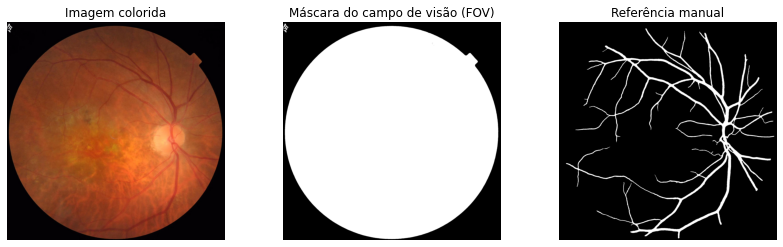

In [12]:
def load_fives(sample_id, split='train'):
    if split not in ('train','test'):
        raise ValueError(f"Split FIVES inválido: {split}")
    stem=str(sample_id)
    image_path=DATA_ROOT/split/'Original'/f'{stem}.png'
    rgb=np.array(Image.open(image_path).convert('RGB'))
    fov_path=DATA_ROOT/split/'Mask'/f'mask_{stem}.png'
    if fov_path.exists():
        fov=np.array(Image.open(fov_path))>0
    else:
        gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
        _,fov=cv2.threshold(gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        fov=fov>0
    gt_path=DATA_ROOT/split/'Ground truth'/f'{stem}.png'
    gt=np.array(Image.open(gt_path).convert('L'))>0 if gt_path.exists() else None
    return rgb, fov, gt

def load_image(sample_id,split='train'):
    return load_fives(sample_id,split)

def natural_sort_key(s):
    # Splits the string into text chunks and digit chunks
    # Converts digit chunks into integers
    return [int(text) if text.isdigit() else text for text in re.split(r'(\d+)', s)]

def available_fives_train_ids(limit=20):
    image_dir = DATA_ROOT / 'train' / 'Original'
    gt_dir    = DATA_ROOT / 'train' / 'Ground truth'
    fov_dir   = DATA_ROOT / 'train' / 'Mask'

    image_stems = {p.stem for p in image_dir.glob('*.png')}
    gt_stems    = {p.stem for p in gt_dir.glob('*.png')}
    fov_stems   = {p.stem[5:] for p in fov_dir.glob('mask_*.png')}  # strip 'mask_'

    ids = sorted(image_stems & gt_stems & fov_stems, key=natural_sort_key)

    if not ids:
        raise FileNotFoundError(
            'Não há IDs FIVES de treino com imagem, FOV e ground truth correspondentes.'
        )

    return ids[:limit]

def split_fives_train_ids(sample_ids,seed=SEED,development_fraction=0.8):
    rng=np.random.default_rng(seed)
    development=[]; validation=[]
    categories=sorted({sample_id.rsplit('_',1)[-1] for sample_id in sample_ids})
    for category in categories:
        group=sorted(sample_id for sample_id in sample_ids if sample_id.rsplit('_',1)[-1]==category)
        shuffled=rng.permutation(group)
        n_dev=int(np.ceil(development_fraction*len(shuffled)))
        development.extend(shuffled[:n_dev])
        validation.extend(shuffled[n_dev:])
    return sorted(development),sorted(validation)

def available_fives_test_ids(limit=20):
    image_dir = DATA_ROOT / 'test' / 'Original'
    gt_dir    = DATA_ROOT / 'test' / 'Ground truth'

    image_stems = {p.stem for p in image_dir.glob('*.png')}
    gt_stems    = {p.stem for p in gt_dir.glob('*.png')}

    missing = sorted(image_stems - gt_stems)
    if missing:
        raise FileNotFoundError(
            f"Ground truth ausente para imagens FIVES de teste: {missing[:5]}"
        )
    if not image_stems:
        raise FileNotFoundError(
            f"Nenhuma imagem FIVES de teste encontrada em {image_dir}"
        )

    return sorted(image_stems)[:limit]

sample_id=available_fives_train_ids()[0]
print('ID de amostra de treino FIVES:', sample_id)
rgb,fov,gt=load_image(sample_id)
print('Imagem:', rgb.shape, rgb.dtype, '| FOV:', fov.sum(), '| pixels rotulados como vaso:', gt.sum())
fig, ax = plt.subplots(1,3,figsize=(14,4))
ax[0].imshow(rgb); ax[0].set_title('Imagem colorida')
ax[1].imshow(fov,cmap='gray'); ax[1].set_title('Máscara do campo de visão (FOV)')
ax[2].imshow(gt,cmap='gray'); ax[2].set_title('Referência manual')
for a in ax: a.axis('off')
plt.show()


## 3. Etapa 1 — realce dos vasos

### 3.1 Canal verde e preenchimento do exterior

Vasos aparecem escuros no canal verde por causa da absorção da hemoglobina. Antes de filtrar, substituímos o fundo externo ao FOV pela média dos pixels internos. Isso reduz respostas falsas na borda circular do campo.

### 3.2 Suavização Gaussiana

Um desvio-padrão pequeno reduz ruído de alta frequência. A suavização excessiva apaga vasos finos; por isso `smooth` também será testado.

### 3.3 CLAHE

A equalização adaptativa com limite de contraste (CLAHE) compensa variações locais de iluminação. `clip` controla a amplificação e `tile` define a grade de blocos. Usamos inicialmente `clip=1.5` para não amplificar tanto a textura do fundo. Após o CLAHE, uma correção gama (`gamma < 1`) clareia os meios-tons sem estourar diretamente os realces. A suavização é leve para preservar vasos finos.

### 3.4 Top-hat morfológico

Invertendo o canal verde, os vasos ficam claros. O top-hat branco subtrai a abertura morfológica da imagem e destaca estruturas claras menores do que o elemento estruturante. `se` é o diâmetro do elemento elíptico em pixels. O valor inicial foi reduzido para 45 px: elementos muito grandes deixam passar variações largas do fundo, enquanto elementos muito pequenos podem deixar vasos largos incompletos. Os valores também são avaliados na análise de sensibilidade.

O Frangi está incluído como alternativa multiescala; não substitui o método principal exigido.


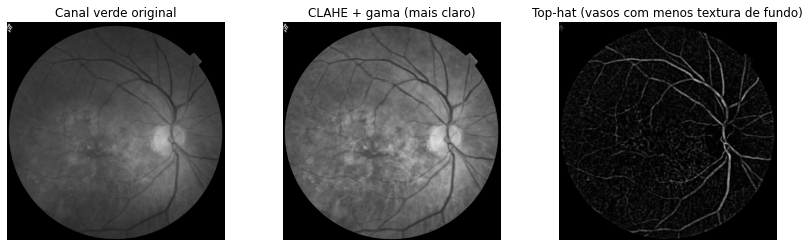

In [13]:
def fill_outside(gray, fov):
    out=gray.copy()
    out[~fov]=int(gray[fov].mean())
    return out

def clahe_gamma(gray, clip=1.5, tile=16, gamma=0.8):
    if gamma<=0:
        raise ValueError('gamma deve ser maior que zero')
    equalized=cv2.createCLAHE(clipLimit=clip,tileGridSize=(tile,tile)).apply(gray)
    lut=np.clip(np.power(np.arange(256,dtype=np.float32)/255.0,gamma)*255.0,0,255).astype(np.uint8)
    return cv2.LUT(equalized,lut)

def enhance(rgb, fov, enhancer='clahe_tophat', clip=1.5, tile=16, se=30, smooth=2.0, gamma=0.7):
    g=fill_outside(rgb[...,1],fov)
    if enhancer=='frangi':
        response=frangi(g.astype(float)/255.0,sigmas=(1,2,3),black_ridges=True)
        response[~fov]=0
        return (255*response/(response.max()+1e-9)).astype(np.uint8)
    if smooth>0:
        g=cv2.GaussianBlur(g,(0,0),smooth)
    if enhancer in ('clahe_tophat','clahe'):
        g=clahe_gamma(g,clip,tile,gamma)
    inv=255-g
    if enhancer in ('clahe_tophat','tophat'):
        kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(se,se))
        inv=cv2.morphologyEx(inv,cv2.MORPH_TOPHAT,kernel)
    inv[~fov]=0
    return cv2.normalize(inv,None,0,255,cv2.NORM_MINMAX)

green=fill_outside(rgb[...,1],fov)
green=cv2.GaussianBlur(green,(0,0),2.0)
green_clahe=clahe_gamma(green,clip=1.5)
green_clahe[~fov]=0
enh=enhance(rgb,fov)
fig,ax=plt.subplots(1,3,figsize=(14,4))
green_original=rgb[...,1].copy(); green_original[~fov]=0
ax[0].imshow(green_original,cmap='gray',vmin=0,vmax=255); ax[0].set_title('Canal verde original')
ax[1].imshow(green_clahe,cmap='gray',vmin=0,vmax=255); ax[1].set_title('CLAHE + gama (mais claro)')
ax[2].imshow(enh,cmap='gray',vmin=0,vmax=255); ax[2].set_title('Top-hat (vasos com menos textura de fundo)')
for a in ax:a.axis('off')
plt.show()


## 4. Etapa 2 — limiarização

A limiarização produz uma máscara binária. Implementamos quatro alternativas:

- **Otsu:** escolhe automaticamente um limiar global pela separação de classes do histograma; pode sofrer porque o fundo ocupa a maior parte da imagem.
- **Percentil:** seleciona os pixels acima de um percentil fixo da resposta realçada.
- **Local:** calcula limiar por vizinhança; adapta-se a iluminação local, mas pode gerar muitos falsos positivos.
- **Histerese:** calcula limiar baixo e alto; pixels fracos só são mantidos quando conectados a regiões fortes. É a configuração inicial do projeto.

Todas as estatísticas de limiarização são calculadas dentro do FOV.


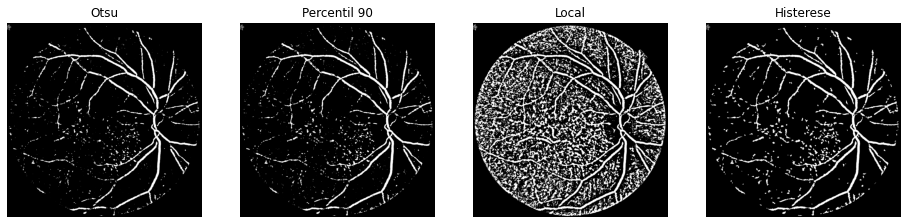

In [14]:
def threshold_image(enh, fov, method='hysteresis', **kw):
    vals=enh[fov]
    if method=='otsu':
        return (enh>threshold_otsu(vals))&fov
    if method=='percentile':
        return (enh>np.percentile(vals,kw.get('p',90)))&fov
    if method=='local':
        loc=threshold_local(enh,kw.get('block',181),offset=-kw.get('off',2))
        return (enh>loc)&(enh>kw.get('floor',10))&fov
    if method=='hysteresis':
        lo=np.percentile(vals,kw.get('p_lo',85)); hi=np.percentile(vals,kw.get('p_hi',93))
        return apply_hysteresis_threshold(enh,lo,hi)&fov
    raise ValueError(method)

methods={'Otsu':('otsu',{}),'Percentil 90':('percentile',{'p':90}),
         'Local':('local',{}),'Histerese':('hysteresis',{'p_lo':85,'p_hi':93})}
fig,ax=plt.subplots(1,4,figsize=(16,4))
for a,(name,(m,kw)) in zip(ax,methods.items()):
    a.imshow(threshold_image(enh,fov,m,**kw),cmap='gray'); a.set_title(name); a.axis('off')
plt.show()


## 5. Etapa 3 — limpeza morfológica dentro do FOV

A limpeza reduz defeitos da máscara bruta. Primeiro afastamos pixels do limite do FOV (`border`) para evitar artefatos de borda. Depois fechamos pequenas lacunas (`close_r`), removemos componentes com área menor que `min_size` e preenchemos buracos menores que `hole`. Ao final, recortamos novamente pelo FOV.

O parâmetro `min_size` é delicado: um valor alto elimina fragmentos de vasos verdadeiros, especialmente vasos finos.


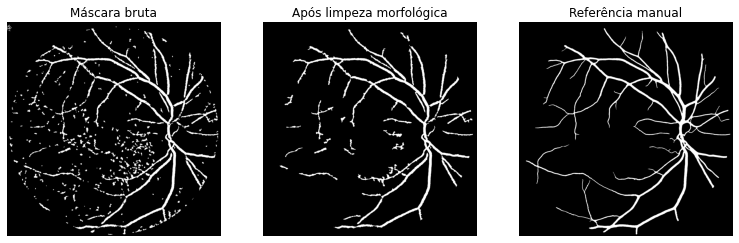

In [15]:
def disk_se(r): return cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(2*r+1,2*r+1))
def erode_fov(mask,r): return cv2.erode(mask.astype(np.uint8),disk_se(r)).astype(bool)
def remove_small(mask,min_size,connectivity=8):
    n,labels,stats,_=cv2.connectedComponentsWithStats(mask.astype(np.uint8),connectivity=connectivity)
    keep=np.zeros(n,dtype=bool); keep[1:]=stats[1:,cv2.CC_STAT_AREA]>=min_size
    return keep[labels]
def fill_small_holes(mask,max_hole):
    return ~remove_small(~mask,max_hole+1,connectivity=4)
def clean_mask(bw,fov,min_size=1000,close_r=4,hole=400,border=14):
    bw=bw&erode_fov(fov,border)
    if close_r>0:
        bw=cv2.morphologyEx(bw.astype(np.uint8),cv2.MORPH_CLOSE,disk_se(close_r)).astype(bool)
    bw=remove_small(bw,min_size)
    bw=fill_small_holes(bw,hole)
    return bw&fov

bw_raw=threshold_image(enh,fov,'hysteresis',p_lo=85,p_hi=93)
bw_clean=clean_mask(bw_raw,fov)
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].imshow(bw_raw,cmap='gray'); ax[0].set_title('Máscara bruta')
ax[1].imshow(bw_clean,cmap='gray'); ax[1].set_title('Após limpeza morfológica')
ax[2].imshow(gt,cmap='gray'); ax[2].set_title('Referência manual')
for a in ax:a.axis('off')
plt.show()


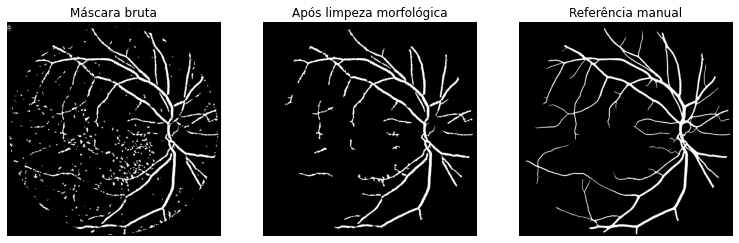

In [16]:
def disk_se(r): return cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(2*r+1,2*r+1))
def erode_fov(mask,r): return cv2.erode(mask.astype(np.uint8),disk_se(r)).astype(bool)
def remove_small(mask,min_size,connectivity=8):
    n,labels,stats,_=cv2.connectedComponentsWithStats(mask.astype(np.uint8),connectivity=connectivity)
    keep=np.zeros(n,dtype=bool); keep[1:]=stats[1:,cv2.CC_STAT_AREA]>=min_size
    return keep[labels]
def fill_small_holes(mask,max_hole):
    return ~remove_small(~mask,max_hole+1,connectivity=4)
def clean_mask(bw,fov,min_size=1000,close_r=4,hole=400,border=14):
    bw=bw&erode_fov(fov,border)
    if close_r>0:
        bw=cv2.morphologyEx(bw.astype(np.uint8),cv2.MORPH_CLOSE,disk_se(close_r)).astype(bool)
    bw=remove_small(bw,min_size)
    bw=fill_small_holes(bw,hole)
    return bw&fov

bw_raw=threshold_image(enh,fov,'hysteresis',p_lo=88,p_hi=93)
bw_clean=clean_mask(bw_raw,fov)
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].imshow(bw_raw,cmap='gray'); ax[0].set_title('Máscara bruta')
ax[1].imshow(bw_clean,cmap='gray'); ax[1].set_title('Após limpeza morfológica')
ax[2].imshow(gt,cmap='gray'); ax[2].set_title('Referência manual')
for a in ax:a.axis('off')
plt.show()


## 6. Etapa 4 — esqueletização, comprimento e ramificações

A esqueletização reduz os vasos a linhas de 1 pixel. Ramos curtos podem surgir devido a irregularidades; a poda remove pontas em iterações, mas também pode remover extremidades verdadeiras. Aqui contamos pixels do esqueleto com pelo menos três vizinhos em 8-conectividade e agrupamos pixels adjacentes de um cruzamento.

O comprimento padrão abaixo é o número de pixels do esqueleto.


Comprimento aproximado (px): 12387.0
Componentes de ramificação: 140


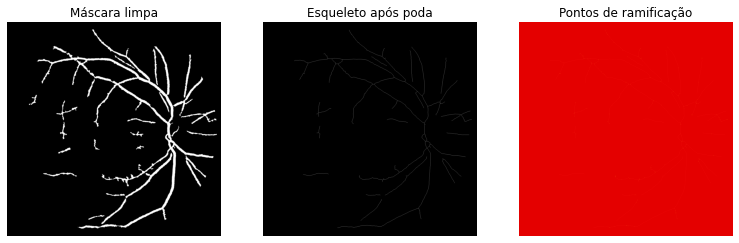

In [ ]:
K8=np.ones((3,3),np.uint8); K8[1,1]=0
def neighbor_count(sk): return convolve(sk.astype(np.uint8),K8,mode='constant')*sk
def prune_skeleton(sk,n):
    sk=sk.copy()
    for _ in range(n):
        sk[(neighbor_count(sk)==1)&sk]=False
    return sk
def branch_points(sk):
    bp=(neighbor_count(sk)>=3)&sk
    n,_=cv2.connectedComponents(bp.astype(np.uint8),connectivity=8)
    return n-1,bp
def vessel_length(sk):
    return float(sk.sum())
def skeleton_stats(mask,prune_n=36):
    sk=skeletonize(mask)
    sk=remove_small(prune_skeleton(sk,prune_n),130)
    n_bp,bp=branch_points(sk)
    return {'skel':sk,'bp':bp,'length':vessel_length(sk),'branches':int(n_bp)}

stats=skeleton_stats(bw_clean,prune_n=36)
print('Comprimento aproximado (px):',stats['length'])
print('Componentes de ramificação:',stats['branches'])
fig,ax=plt.subplots(1,3,figsize=(13,4))
ax[0].imshow(bw_clean,cmap='gray'); ax[0].set_title('Máscara limpa')
ax[1].imshow(stats['skel'],cmap='gray'); ax[1].set_title('Esqueleto após poda')
ax[2].imshow(stats['skel'],cmap='gray'); ax[2].imshow(stats['bp'],cmap='autumn',alpha=.9); ax[2].set_title('Pontos de ramificação')
for a in ax:a.axis('off')
plt.show()


## 7. Pipeline integrado e métricas

As métricas binárias são calculadas somente no FOV. `Dice` e `IoU` medem sobreposição; sensibilidade é a fração de vasos de referência recuperados; especificidade é a fração de fundo corretamente rejeitada. Comprimento e ramificações são comparados com a referência manual, esqueletizada e podada pelo mesmo procedimento. Esses indicadores topológicos são aproximados e dependem da definição de poda e conectividade.


In [18]:
DEFAULT={'enhancer':'clahe_tophat','clip':1.5,'tile':16,'se':45,'smooth':2.0,'gamma':0.7,
         'method':'hysteresis','p_hi':93,'p_lo':85,'min_size':1000,'close_r':4,'hole':400,'border':14,'prune_n':36}
def run_pipeline(rgb,fov,**kwargs):
    p={**DEFAULT,**kwargs}
    response=enhance(rgb,fov,p['enhancer'],p['clip'],p['tile'],p['se'],p['smooth'],p['gamma'])
    tkw={k:p[k] for k in ('p','p_hi','p_lo','block','off','floor') if k in p}
    raw=threshold_image(response,fov,p['method'],**tkw)
    bw=clean_mask(raw,fov,p['min_size'],p['close_r'],p['hole'],p['border'])
    return {'enh':response,'bw0':raw,'bw':bw,**skeleton_stats(bw,p['prune_n'])}
def segmentation_metrics(pred,gt,fov):
    p,g=pred[fov],gt[fov]
    tp=np.sum(p&g); fp=np.sum(p&~g); fn=np.sum(~p&g); tn=np.sum(~p&~g)
    return {'dice':2*tp/(2*tp+fp+fn+1e-9),'iou':tp/(tp+fp+fn+1e-9),
            'sensitivity':tp/(tp+fn+1e-9),'specificity':tn/(tn+fp+1e-9),
            'accuracy':(tp+tn)/(tp+tn+fp+fn+1e-9)}
def relative_error(a,b): return abs(a-b)/max(float(b),1e-9)
def evaluate_ids(ids,split='train',**kwargs):
    rows=[]
    for idx in ids:
        image,mask,ref=load_image(idx,split=split)
        if ref is None:
            raise FileNotFoundError(f"Ground truth não disponível para {DATASET} {split} {idx}")
        result=run_pipeline(image,mask,**kwargs)
        reference=skeleton_stats(ref&mask,{**DEFAULT,**kwargs}['prune_n'])
        row=segmentation_metrics(result['bw'],ref,mask)
        row.update(id=idx,length=result['length'],reference_length=reference['length'],
                   length_error=relative_error(result['length'],reference['length']),
                   branches=result['branches'],reference_branches=reference['branches'],
                   branch_error=relative_error(result['branches'],reference['branches']))
        rows.append(row)
    return pd.DataFrame(rows)

one=run_pipeline(rgb,fov)
print(segmentation_metrics(one['bw'],gt,fov))


{'dice': np.float64(0.7738041852903322), 'iou': np.float64(0.6310608599439312), 'sensitivity': np.float64(0.8033812679246789), 'specificity': np.float64(0.9718444642749907), 'accuracy': np.float64(0.9560979376826375)}


## 8. Comparação de alternativas no conjunto de desenvolvimento

Os IDs de treino são os nomes completos obtidos pela interseção de imagem, FOV e ground truth. No FIVES, a divisão é aleatória, reproduzível e estratificada pelos sufixos de categoria `_A`, `_D`, `_G` e `_N`: cerca de 80% de cada categoria para desenvolvimento e 20% para validação interna. Comparamos realces e limiarizadores somente no desenvolvimento; o teste oficial não participa da seleção de parâmetros.


In [19]:
FIVES_TRAIN_IDS=available_fives_train_ids(limit=LIMIT_SAMPLES)
DEV_IDS,VALIDATION_IDS=split_fives_train_ids(FIVES_TRAIN_IDS,SEED)
TEST_IDS=available_fives_test_ids(limit=LIMIT_SAMPLES)
print(f'FIVES: {len(DEV_IDS)} desenvolvimento, {len(VALIDATION_IDS)} validação e {len(TEST_IDS)} teste oficial')
print('Treino por categoria:',{category:sum(sample_id.endswith('_'+category) for sample_id in FIVES_TRAIN_IDS) for category in ('A','D','G','N')})
print('Desenvolvimento por categoria:',{category:sum(sample_id.endswith('_'+category) for sample_id in DEV_IDS) for category in ('A','D','G','N')})
print('Validação por categoria:',{category:sum(sample_id.endswith('_'+category) for sample_id in VALIDATION_IDS) for category in ('A','D','G','N')})
NOISE_IDS=sorted(np.random.default_rng(SEED+1).choice(DEV_IDS,size=min(5,len(DEV_IDS)),replace=False).tolist())
def compare_variants(ids,variants,base_kwargs):
    results={name:evaluate_ids(ids,**{**base_kwargs,**params}) for name,params in variants.items()}
    summary=[]
    for name,df in results.items():
        row={'variant':name}
        for metric in ['dice','iou','sensitivity','specificity','length_error','branch_error']:
            row[metric+'_mean']=df[metric].mean(); row[metric+'_sd']=df[metric].std()
        summary.append(row)
    summary=pd.DataFrame(summary).sort_values('dice_mean',ascending=False)
    best=summary.iloc[0]['variant']; tests=[]
    for name,df in results.items():
        if name==best: continue
        try: p=float(wilcoxon(results[best]['dice'],df['dice']).pvalue)
        except ValueError: p=np.nan
        tests.append({'best':best,'other':name,'p_wilcoxon':p})
    return summary,pd.DataFrame(tests),results

enhancer_variants={'Verde + CLAHE + gama + top-hat':{'enhancer':'clahe_tophat'},
                   'Verde + top-hat':{'enhancer':'tophat'},'Verde + CLAHE + gama':{'enhancer':'clahe'},'Frangi':{'enhancer':'frangi'}}
threshold_variants={'Otsu':{'method':'otsu'},'Percentil 90':{'method':'percentile','p':90},
                    'Local adaptativo':{'method':'local'},'Histerese':{'method':'hysteresis'}}
enh_summary,enh_tests,enh_details=compare_variants(DEV_IDS,enhancer_variants,{'method':'hysteresis'})
thr_summary,thr_tests,thr_details=compare_variants(DEV_IDS,threshold_variants,{'enhancer':'clahe_tophat'})
display(enh_summary.round(3)); display(enh_tests.round(4))
display(thr_summary.round(3)); display(thr_tests.round(4))


FIVES: 16 desenvolvimento, 4 validação e 20 teste oficial
Treino por categoria: {'A': 20, 'D': 0, 'G': 0, 'N': 0}
Desenvolvimento por categoria: {'A': 16, 'D': 0, 'G': 0, 'N': 0}
Validação por categoria: {'A': 4, 'D': 0, 'G': 0, 'N': 0}


,variant,dice_mean,dice_sd,iou_mean,iou_sd,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,length_error_mean,length_error_sd,branch_error_mean,branch_error_sd
0,Verde + CLAHE + gama + top-hat,0.728,0.086,0.579,0.101,0.756,0.049,0.964,0.016,0.282,0.095,0.768,0.590
1,Verde + top-hat,0.701,0.096,0.548,0.107,0.713,0.066,0.964,0.017,0.320,0.096,0.674,0.521
2,Verde + CLAHE + gama,0.336,0.095,0.206,0.071,0.376,0.095,0.904,0.022,0.345,0.141,1.279,0.810
3,Frangi,0.022,0.088,0.013,0.053,0.025,0.100,0.992,0.031,0.966,0.137,1.198,0.792


,best,other,p_wilcoxon
0,Verde + CLAHE + gama + top-hat,Verde + top-hat,0.0
1,Verde + CLAHE + gama + top-hat,Verde + CLAHE + gama,0.0
2,Verde + CLAHE + gama + top-hat,Frangi,0.0


,variant,dice_mean,dice_sd,iou_mean,iou_sd,sensitivity_mean,sensitivity_sd,specificity_mean,specificity_sd,length_error_mean,length_error_sd,branch_error_mean,branch_error_sd
3,Histerese,0.728,0.086,0.579,0.101,0.756,0.049,0.964,0.016,0.282,0.095,0.768,0.590
1,Percentil 90,0.715,0.082,0.562,0.095,0.641,0.063,0.984,0.010,0.451,0.050,0.306,0.222
0,Otsu,0.673,0.070,0.510,0.078,0.605,0.086,0.979,0.027,0.446,0.200,0.860,0.978
2,Local adaptativo,0.394,0.063,0.247,0.049,0.913,0.031,0.688,0.040,2.057,0.598,16.394,6.036


,best,other,p_wilcoxon
0,Histerese,Otsu,0.0000
1,Histerese,Percentil 90,0.0155
2,Histerese,Local adaptativo,0.0000


## 9. Análise de sensibilidade dos parâmetros

Fazemos varredura univariada: variamos um parâmetro de cada vez, mantendo os demais nos valores padrão. A seleção de cada valor maximiza o Dice médio no conjunto de desenvolvimento. Esse método é transparente, mas não procura interações entre parâmetros nem garante ótimo global. **Não** use os IDs de validação nem o teste oficial para tomar decisões de ajuste.


clip → 6.0 | Dice 0.7321
tile → 16 | Dice 0.7279
gamma → 0.7 | Dice 0.7279
se → 30 | Dice 0.7535
smooth → 2 | Dice 0.7279
p_hi → 93 | Dice 0.7279
min_size → 1000 | Dice 0.7279
prune_n → 0 | Dice 0.7279


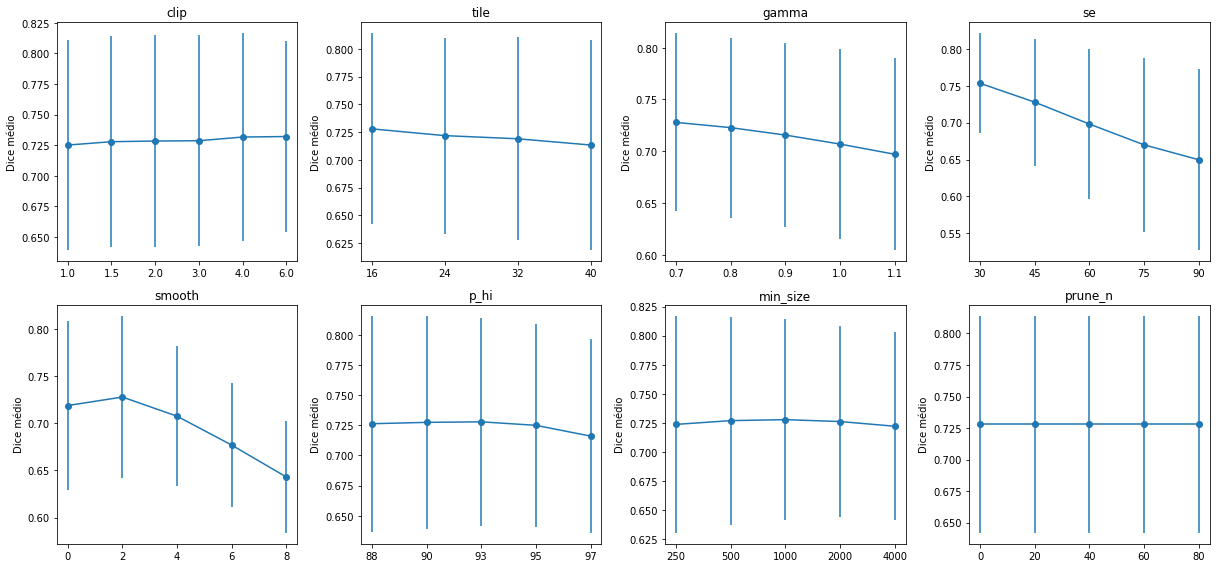

In [20]:
PARAM_GRID={'clip':[1,1.5,2,3,4,6],'tile':[16,24,32,40],'gamma':[0.7,0.8,0.9,1.0,1.1],
            'se':[30,45,60,75,90],'smooth':[0,2,4,6,8],'p_hi':[88,90,93,95,97],
            'min_size':[250,500,1000,2000,4000],'prune_n':[0,20,40,60,80]}
def sweep_parameter(ids,param,values):
    rows=[]
    for value in values:
        df=evaluate_ids(ids,**{param:value})
        rows.append({'param':param,'value':value,'dice':df.dice.mean(),'dice_sd':df.dice.std(),
                     'iou':df.iou.mean(),'sensitivity':df.sensitivity.mean(),'specificity':df.specificity.mean(),
                     'length_error':df.length_error.mean(),'branch_error':df.branch_error.mean()})
    return pd.DataFrame(rows)

sensitivity_tables={}
selected={}
for param,values in PARAM_GRID.items():
    table=sweep_parameter(DEV_IDS,param,values)
    sensitivity_tables[param]=table
    selected[param]=table.loc[table.dice.idxmax(),'value'].item()
    print(param,'→',selected[param],'| Dice',round(table.dice.max(),4))

fig,axes=plt.subplots(2,4,figsize=(17,8)); axes=axes.ravel()
for ax,(param,table) in zip(axes,sensitivity_tables.items()):
    x=np.arange(len(table)); ax.errorbar(x,table.dice,yerr=table.dice_sd,marker='o')
    ax.set_xticks(x); ax.set_xticklabels(table.value); ax.set_title(param); ax.set_ylabel('Dice médio')
for ax in axes[len(sensitivity_tables):]: ax.axis('off')
plt.tight_layout(); plt.show()


## 10. Estudo de ruído e PSNR

Para compreender robustez, adicionamos ruído Gaussiano de desvio-padrão σ=0, 10, 20 e 30 níveis de intensidade a cinco imagens do grupo de desenvolvimento. Comparamos nenhum filtro, Gaussiano, mediana e bilateral. O PSNR quantifica diferença entre canal verde processado e original dentro do FOV. Quando σ=0 e não há filtro, as imagens coincidem; o notebook usa 99 dB como valor sentinela para igualdade exata.

Este experimento simulado mede sensibilidade a ruído sintético e não substitui imagens com ruído real de aquisição.


In [21]:
denoisers={'Nenhum':lambda g:g,'Gaussiano σ=1':lambda g:cv2.GaussianBlur(g,(0,0),1),
           'Mediana 3×3':lambda g:cv2.medianBlur(g,3),
           'Bilateral':lambda g:cv2.bilateralFilter(g,5,25,3)}
def psnr(a,b,mask):
    mse=np.mean((a[mask].astype(float)-b[mask].astype(float))**2)
    return 99.0 if mse==0 else 10*np.log10(255.0**2/mse)
noise_rows=[]
for idx in NOISE_IDS:
    image,mask,ref=load_image(idx)
    green=image[...,1]
    for sigma in [0,10,20,30]:
        sample_seed=sum(ord(char) for char in str(idx))
        rng=np.random.default_rng(SEED+sample_seed+sigma)
        noisy=green if sigma==0 else np.clip(green.astype(float)+rng.normal(0,sigma,green.shape),0,255).astype(np.uint8)
        for name,denoise in denoisers.items():
            filtered=denoise(noisy)
            image2=image.copy(); image2[...,1]=filtered
            pred=run_pipeline(image2,mask)['bw']
            noise_rows.append({'id':idx,'sigma':sigma,'filter':name,'psnr':psnr(filtered,green,mask),
                               'dice':segmentation_metrics(pred,ref,mask)['dice']})
noise_df=pd.DataFrame(noise_rows)
noise_summary=noise_df.groupby(['sigma','filter'])[['psnr','dice']].mean().reset_index()
display(noise_summary.round(3))


,sigma,filter,psnr,dice
0,0,Bilateral,48.558,0.741
1,0,Gaussiano σ=1,48.328,0.741
2,0,Mediana 3×3,52.009,0.744
3,0,Nenhum,99.000,0.744
4,10,Bilateral,37.266,0.735
5,10,Gaussiano σ=1,38.471,0.735
6,10,Mediana 3×3,35.696,0.732
7,10,Nenhum,28.119,0.736
8,20,Bilateral,27.733,0.689
9,20,Gaussiano σ=1,33.041,0.691


## 11. Congelar parâmetros e avaliar validação/teste

Combinamos os melhores valores marginais obtidos no grupo de desenvolvimento com os parâmetros padrão que não foram variados. Primeiro avaliamos uma única vez a validação interna reservada. Depois de congelar os parâmetros, avaliamos o split oficial de teste do FIVES separadamente, sem usá-lo para ajustes. Esta célula deve vir **depois** de todas as decisões de método e parâmetro.

Se quiser aderir estritamente ao relatório original, que congelou o padrão sem otimização, substitua `FINAL_PARAMS` pelos valores padrão de `DEFAULT`. Aqui usamos a varredura de desenvolvimento para que o notebook mostre como escolher e congelar parâmetros.


In [22]:
FINAL_PARAMS={**DEFAULT,**selected}
print('Parâmetros congelados:',json.dumps(FINAL_PARAMS,indent=2))
validation_df=evaluate_ids(VALIDATION_IDS,**FINAL_PARAMS)
validation_summary=validation_df[['dice','iou','sensitivity','specificity','length_error','branch_error']].agg(['mean','std']).T
print('Resumo da validação interna:')
display(validation_summary.round(4))
display(validation_df.round(4))
test_df=evaluate_ids(TEST_IDS,split='test',**FINAL_PARAMS)
test_summary=test_df[['dice','iou','sensitivity','specificity','length_error','branch_error']].agg(['mean','std']).T
print('Resumo do teste oficial FIVES (somente avaliação, sem reajuste):')
display(test_summary.round(4))


Parâmetros congelados: {
  "enhancer": "clahe_tophat",
  "clip": 6.0,
  "tile": 16,
  "se": 30,
  "smooth": 2,
  "gamma": 0.7,
  "method": "hysteresis",
  "p_hi": 93,
  "p_lo": 85,
  "min_size": 1000,
  "close_r": 4,
  "hole": 400,
  "border": 14,
  "prune_n": 0
}
Resumo da validação interna:


,mean,std
dice,0.7932,0.0294
iou,0.6580,0.0400
sensitivity,0.7628,0.0448
specificity,0.9807,0.0024
length_error,0.1288,0.0526
branch_error,0.9306,0.3899


,dice,iou,sensitivity,specificity,accuracy,id,length,reference_length,length_error,branches,reference_branches,branch_error
0,0.8230,0.6992,0.8220,0.9789,0.9621,11_A,23172.0,26595.0,0.1287,329,171,0.9240
1,0.8072,0.6768,0.7665,0.9838,0.9601,18_A,20672.0,21954.0,0.0584,376,190,0.9789
2,0.7879,0.6501,0.7477,0.9816,0.9561,3_A,20975.0,25730.0,0.1848,337,235,0.4340
3,0.7547,0.6061,0.7151,0.9787,0.9507,7_A,20520.0,23952.0,0.1433,365,153,1.3856


Resumo do teste oficial FIVES (somente avaliação, sem reajuste):


,mean,std
dice,0.6145,0.2246
iou,0.4752,0.2072
sensitivity,0.5748,0.2336
specificity,0.9815,0.0078
length_error,0.2920,0.3020
branch_error,1.1515,1.0940


## 12. Análise de falhas

Selecionamos automaticamente o pior e o melhor caso da validação interna apenas para **descrever** o comportamento. O mapa de erro usa verde para verdadeiro positivo, vermelho para falso positivo e azul para falso negativo; pixels fora do FOV aparecem em cinza. A sensibilidade por largura estima a largura local pela transformada de distância da referência e calcula a fração do esqueleto de referência recuperada com tolerância de um pixel.


Pior caso de validação: 7_A | melhor caso de validação: 11_A


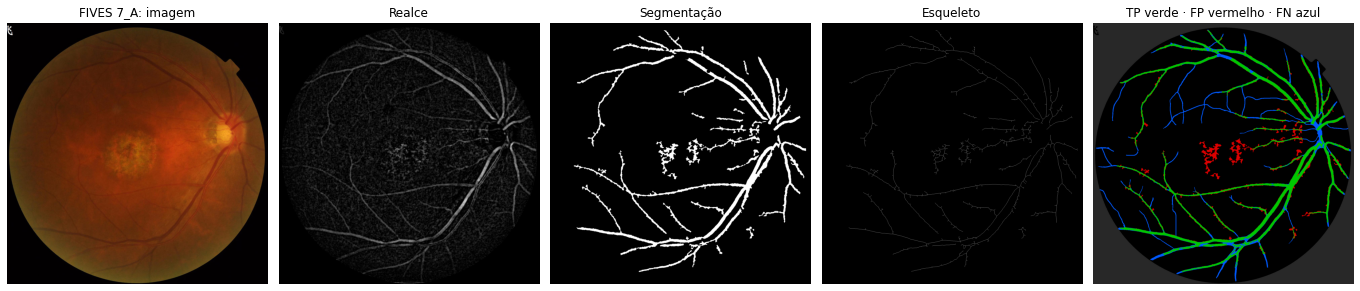

Métricas: {'dice': np.float64(0.7547462175332046), 'iou': np.float64(0.606098313580774), 'sensitivity': np.float64(0.7151331783894934), 'specificity': np.float64(0.9786593642620768), 'accuracy': np.float64(0.9507131258525611)}
Recall por largura:


,width_px,reference_skeleton_pixels,recall
0,0–11,11999,0.467956
1,11–18,4743,0.902172
2,18–25,5450,0.971009
3,25–108,1577,0.944832


Maiores componentes FP (coordenadas em pixels):


,x_px,y_px,area_px
0,926,1038,10070
1,1122,1024,6338
2,1158,939,1511
3,964,1198,1188
4,1612,1011,1070


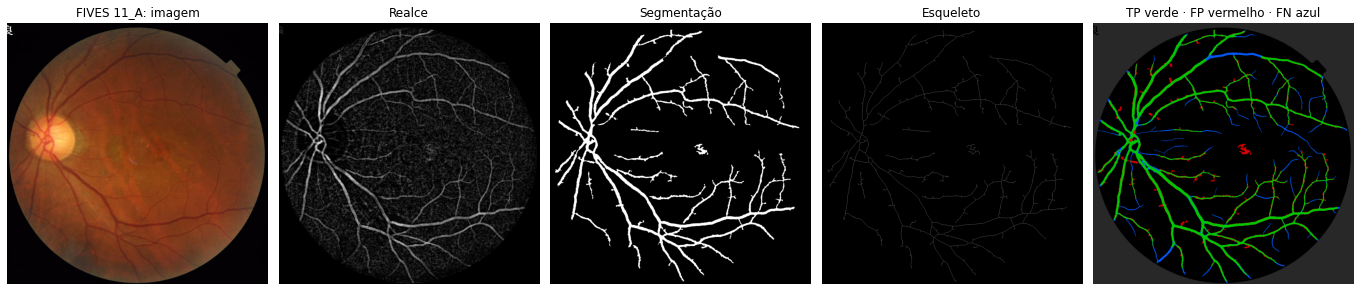

Métricas: {'dice': np.float64(0.8229661826631582), 'iou': np.float64(0.699186523395906), 'sensitivity': np.float64(0.8219554505747576), 'specificity': np.float64(0.9789073558906949), 'accuracy': np.float64(0.9620753653803389)}
Recall por largura:


,width_px,reference_skeleton_pixels,recall
0,0–11,14465,0.631248
1,11–18,6383,0.933260
2,18–25,5146,0.974543
3,25–108,540,0.996296


Maiores componentes FP (coordenadas em pixels):


,x_px,y_px,area_px
0,1187,994,3580
1,710,1567,670
2,327,1091,618
3,211,674,579
4,450,715,466


In [23]:
def error_map(pred,gt,fov):
    out=np.zeros(pred.shape+(3,),np.uint8)
    out[pred&gt]=(0,200,0)       # verdadeiro positivo (RGB verde)
    out[pred&~gt]=(220,0,0)     # falso positivo
    out[~pred&gt]=(0,90,255)     # falso negativo
    out[~fov]=(40,40,40)
    return out

def recall_by_width(pred,gt,fov,edges=(0,11,18,25,108)):
    distance=cv2.distanceTransform(gt.astype(np.uint8),cv2.DIST_L2,5)
    sk=skeletonize(gt)&fov
    widths=2*distance[sk]
    hit=cv2.dilate(pred.astype(np.uint8),np.ones((11,11),np.uint8)).astype(bool)[sk]
    rows=[]
    for lo,hi in zip(edges[:-1],edges[1:]):
        group=(widths>=lo)&(widths<hi)
        rows.append({'width_px':f'{lo}–{hi}','reference_skeleton_pixels':int(group.sum()),
                     'recall':float(hit[group].mean()) if group.any() else np.nan})
    return pd.DataFrame(rows)

def worst_fp_components(pred,gt,fov,k=5):
    tolerance=disk_se(7)
    fp=pred&~cv2.dilate(gt.astype(np.uint8),tolerance).astype(bool)&fov
    fp=remove_small(fp,200)
    n,labels,stats,centroids=cv2.connectedComponentsWithStats(fp.astype(np.uint8),connectivity=8)
    order=np.argsort(-stats[1:,cv2.CC_STAT_AREA])[:k]+1
    return pd.DataFrame([{'x_px':int(centroids[i,0]),'y_px':int(centroids[i,1]),
                          'area_px':int(stats[i,cv2.CC_STAT_AREA])} for i in order])

worst_id=validation_df.loc[validation_df.dice.idxmin(),'id']
best_id=validation_df.loc[validation_df.dice.idxmax(),'id']
print('Pior caso de validação:',worst_id,'| melhor caso de validação:',best_id)
def show_case(idx):
    image,mask,ref=load_image(idx,split='train')
    result=run_pipeline(image,mask,**FINAL_PARAMS)
    fig,ax=plt.subplots(1,5,figsize=(19,4))
    ax[0].imshow(image); ax[0].set_title(f'{DATASET} {idx}: imagem')
    ax[1].imshow(result['enh'],cmap='gray'); ax[1].set_title('Realce')
    ax[2].imshow(result['bw'],cmap='gray'); ax[2].set_title('Segmentação')
    ax[3].imshow(result['skel'],cmap='gray'); ax[3].set_title('Esqueleto')
    ax[4].imshow(error_map(result['bw'],ref,mask)); ax[4].set_title('TP verde · FP vermelho · FN azul')
    for a in ax:a.axis('off')
    plt.tight_layout(); plt.show()
    print('Métricas:',segmentation_metrics(result['bw'],ref,mask))
    print('Recall por largura:'); display(recall_by_width(result['bw'],ref,mask))
    print('Maiores componentes FP (coordenadas em pixels):'); display(worst_fp_components(result['bw'],ref,mask))
    return result
worst_result=show_case(worst_id)
best_result=show_case(best_id)


### Interpretação guiada

Ao inspecionar os mapas, procure: vasos finos perdidos (azul); respostas falsas em lesões, reflexos ou disco óptico (vermelho); anéis junto à borda do FOV; vasos largos com lacunas centrais; fusões de vasos próximos; e ramos espúrios no esqueleto. Para cada falha registrada, escreva a evidência observada, a causa provável, a ligação com o operador usado e uma possível melhoria. Não declare causa anatômica apenas com base em uma coordenada de falso positivo.

A análise de falhas usa somente a validação interna para descrever limitações; não use os casos reservados para reajustar parâmetros depois da avaliação. O teste oficial FIVES permanece separado e é reportado apenas como avaliação final.


## 13. Salvar tabelas, parâmetros e figuras

Salvamos CSVs e parâmetros no diretório `resultados/`. O notebook também salva uma imagem de exemplo do pipeline. Para levar os resultados ao computador, é possível compactar a pasta e iniciar o download pelo Colab.


In [24]:
OUT=Path(FOLDER_PATH) / DATASET / 'resultados'; FIG=OUT/'figuras'; TAB=OUT/'tabelas'
FIG.mkdir(parents=True,exist_ok=True); TAB.mkdir(parents=True,exist_ok=True)
split_manifest={'seed':SEED,'development_ids':DEV_IDS,'validation_ids':VALIDATION_IDS,'test_ids':TEST_IDS}
with open(OUT/'divisao_fives.json','w') as f: json.dump(split_manifest,f,indent=2)
enh_summary.to_csv(TAB/'comparacao_realce.csv',index=False)
enh_tests.to_csv(TAB/'comparacao_realce_wilcoxon.csv',index=False)
thr_summary.to_csv(TAB/'comparacao_limiar.csv',index=False)
thr_tests.to_csv(TAB/'comparacao_limiar_wilcoxon.csv',index=False)
noise_summary.to_csv(TAB/'ruido_psnr.csv',index=False)
noise_df.to_csv(TAB/'ruido_por_imagem.csv',index=False)
validation_df.to_csv(TAB/'validacao_por_imagem.csv',index=False)
validation_summary.to_csv(TAB/'validacao_resumo.csv')
test_df.to_csv(TAB/'teste_oficial_por_imagem.csv',index=False)
test_summary.to_csv(TAB/'teste_oficial_resumo.csv')
all_sensitivity=pd.concat(sensitivity_tables.values(),ignore_index=True)
all_sensitivity.to_csv(TAB/'sensibilidade.csv',index=False)
for name,table in sensitivity_tables.items(): table.to_csv(TAB/f'sensibilidade_{name}.csv',index=False)
with open(OUT/'parametros_finais.json','w') as f: json.dump(FINAL_PARAMS,f,indent=2)
for idx in (worst_id,best_id):
    image,mask,ref=load_image(idx,split='train'); result=run_pipeline(image,mask,**FINAL_PARAMS)
    fig,ax=plt.subplots(1,5,figsize=(18,4))
    ax[0].imshow(image); ax[0].set_title('Imagem')
    ax[1].imshow(result['enh'],cmap='gray'); ax[1].set_title('Realce')
    ax[2].imshow(result['bw'],cmap='gray'); ax[2].set_title('Segmentação')
    ax[3].imshow(result['skel'],cmap='gray'); ax[3].set_title('Esqueleto')
    ax[4].imshow(error_map(result['bw'],ref,mask)); ax[4].set_title('Mapa de erros')
    for a in ax:a.axis('off')
    plt.tight_layout(); fig.savefig(FIG/f'pipeline_{idx}.png',dpi=140,bbox_inches='tight'); plt.close(fig)
print('Arquivos salvos em',OUT)


Arquivos salvos em \content\FIVES\resultados


## 14. (Opcional) Exportar previsões do teste oficial

Exporta previsões usando os parâmetros congelados e os nomes reais dos arquivos no split `test` (por exemplo, `100_D.png`). A execução não envia arquivos a nenhum serviço.


In [25]:
MAKE_TEST_PREDICTIONS=False
if MAKE_TEST_PREDICTIONS:
    pred_dir=OUT/f'pred_{DATASET}'; pred_dir.mkdir(exist_ok=True)
    for idx in TEST_IDS:
        image,mask,_=load_fives(idx,split='test')
        output_name=f'{idx}.png'
        pred=run_pipeline(image,mask,**FINAL_PARAMS)['bw']
        Image.fromarray(pred.astype(np.uint8)*255).save(pred_dir/output_name)
    zip_path=shutil.make_archive(str(OUT/f'pred_{DATASET}'),'zip',root_dir=pred_dir)
    print('ZIP de previsões:',zip_path)
    try:
        from google.colab import files
        files.download(zip_path)
    except ImportError:
        print('Fora do Colab. O ZIP está em',zip_path)


## 15. Conclusões e limitações

Ao finalizar a execução, descreva os resultados produzidos pelas células, sem substituir os valores reais por valores de exemplo. Discuta qual realce e limiarização tiveram melhor desempenho; se as diferenças pareadas foram estatisticamente claras; quais parâmetros foram sensíveis; como Dice, sensibilidade e especificidade se comportaram na validação interna e no teste oficial; e quais falhas aparecem nos mapas e por largura de vaso.

Limitações importantes: divisão aleatória interna de treino/validação dependente da semente; uma anotação manual por imagem; parâmetros em pixels dependentes da resolução; contagem aproximada de comprimento; ramos definidos por vizinhança de oito pixels; e ausência de validação externa. No FIVES, o split oficial de teste é avaliado após congelar os parâmetros. O método é para processamento e avaliação acadêmica, não diagnóstico clínico.

## Referências

[1] FIVES: A Fundus Image Dataset for Artificial Intelligence based Vessel Segmentation: <https://www.nature.com/articles/s41597-022-01564-3/>.\n
[2] Espelho Kaggle utilizado para download; <https://www.kaggle.com/datasets/nikitamanaenkov/fundus-image-dataset-for-vessel-segmentation>.\n
